# Чтобы проанализировать данные опроса пользователей приложения, была построена воронка пользовательского опыта

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

In [26]:
df=pd.read_excel('Кейс.xlsx').dropna(subset=[df.columns[1]])
n=len(df)
col_score=[c for c in df.columns if 'удобно' in c.lower()][0]
col_ai=[c for c in df.columns if 'почему приложение поставило' in c.lower()][0]
col_useful= [c for c in df.columns if 'полезнее' in c.lower()][0]
col_return =[c for c in df.columns if 'доступно завтра' in c.lower()][0]

In [27]:
s1 = pd.to_numeric(df[col_score], errors='coerce')
v1 = round((len(s1[s1 >= 3]) / n) * 100, 1)
s2 = df[col_ai].astype(str)
v2 = round((len(s2[s2.str.contains('Да, полностью|В целом понятно', na=False)]) / n) * 100, 1)
s3 = df[col_useful].astype(str)
v3 = round((len(s3[s3.str.contains('Разбор по критериям', na=False)]) / n) * 100, 1)
s4 = df[col_return].astype(str)
v4 = round((len(s4[s4.str.contains('Да, обязательно|Скорее да', na=False)]) /n) * 100, 1)

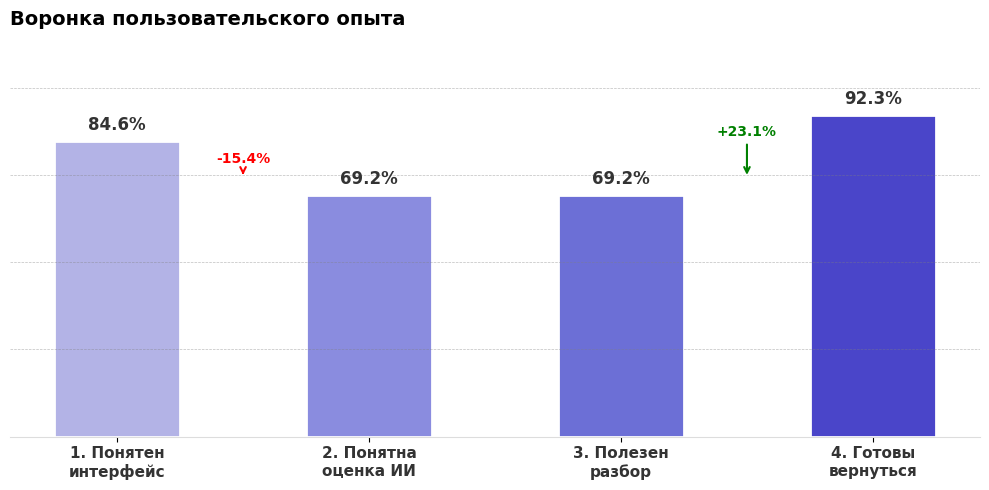

In [29]:
labels = ['1. Понятен\nинтерфейс', '2. Понятна\nоценка ИИ', '3. Полезен\nразбор', '4. Готовы\nвернуться']
vals= [v1, v2, v3, v4]
fig, ax = plt.subplots(figsize=(10, 5))
colors =['#B3B3E6', '#8A8CDF', '#6C6FD6', '#4A45C9']
bars= ax.bar(labels, vals, color=colors, width=0.5, edgecolor='white', linewidth=2)
for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f'{val}%', ha='center', va='bottom', fontweight='bold', fontsize=12, color='#333333')
ax.set_ylim(0, 110)
ax.set_yticks([])
ax.set_title('Воронка пользовательского опыта', loc='left', fontsize=14, pad=20, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
for y in [25, 50, 75, 100]:
    ax.axhline(y, color='gray',linestyle='--',linewidth=0.5,alpha=0.5)
for i in range(len(vals) - 1):
    diff = vals[i+1] - vals[i]
    color = 'green' if diff > 0 else 'red'
    sign = '+' if diff > 0 else ''
    if abs(diff) > 0.5:
        x_mid = i + 0.5
        plt.annotate(f'{sign}{round(diff, 1)}%',
                     xy=(x_mid, min(vals[i], vals[i+1]) + 5),
                     xytext=(x_mid, max(vals[i], vals[i+1]) - 5),
                     ha='center', va='center', fontsize=10,
                     fontweight='bold', color=color,
                     arrowprops=dict(arrowstyle="->", color=color, lw=1.5))
plt.xticks(fontsize=11, fontweight='bold', color='#333333')
plt.tight_layout()
plt.show()

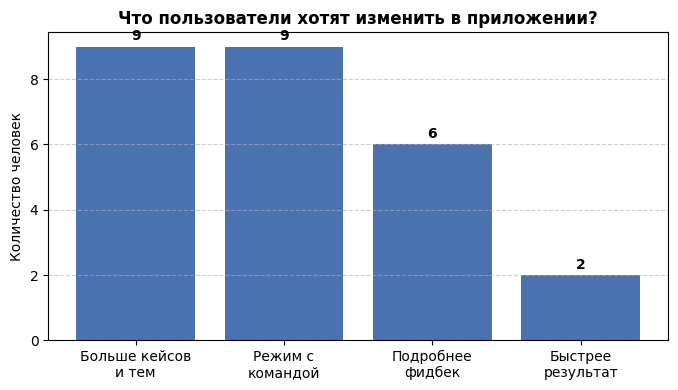

<Figure size 600x600 with 0 Axes>

In [32]:
c_score= [c for c in df.columns if 'удобно' in c.lower()][0]
c_change =[c for c in df.columns if 'должно измениться' in c.lower()][0]
c_complex=[c for c in df.columns if 'самым сложным' in c.lower()][0]
reqs = {
    'Больше кейсов\nи тем': df[c_change].str.contains('Больше кейсов',na=False).sum(),
    'Режим с\nкомандой': df[c_change].str.contains('Режим с командой',na=False).sum(),
    'Подробнее\nфидбек': df[c_change].str.contains('Подробнее фидбек',na=False).sum(),
    'Быстрее\nрезультат': df[c_change].str.contains('Быстрее получать',na=False).sum()
}
plt.figure(figsize=(8, 4))
plt.bar(reqs.keys(), reqs.values(), color='#4A72B0')
plt.title('Что пользователи хотят изменить в приложении?', fontsize=12, fontweight='bold')
plt.ylabel('Количество человек')
plt.grid(axis='y', linestyle='--',alpha=0.6)
for i, v in enumerate(reqs.values()):
    plt.text(i, v + 0.2, str(v), ha='center', fontweight='bold')
plt.show()
df_bad= df[pd.to_numeric(df[c_score],errors='coerce') == 2]
hard_parts =df_bad[c_complex].value_counts()

plt.figure(figsize=(6, 6))
plt.show()